### Проверка устойчивости выводов EDA

Проверяем, что меняется при другом весе пациентов, в разных группах поступления и при исключении отдельных типов переводов. Используем только обучающую часть из `eda_fundamental.ipynb`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import GroupKFold, GroupShuffleSplit

In [2]:
'''загрузка данных'''
data_dir = Path("data/raw")
if not data_dir.is_dir():
    data_dir = Path("../data/raw")

encounters = pd.read_csv(
    data_dir / "diabetic_data.csv",
    keep_default_na=False,
    na_values=["?"],
    dtype={
        "diag_1": "string",
        "diag_2": "string",
        "diag_3": "string",
        "payer_code": "string",
    },)

mapping_rows = pd.read_csv(
    data_dir / "IDS_mapping.csv",
    header=None,
    names=["code", "description"],
    dtype="string",
    keep_default_na=False,)

is_section_header = mapping_rows["description"].eq("description")
mapping_rows["field"] = mapping_rows["code"].where(is_section_header).ffill()

is_code = mapping_rows["code"].str.fullmatch(r"\d+")
id_mapping = mapping_rows.loc[is_code, ["field", "code", "description"]].copy()
id_mapping["code"] = id_mapping["code"].astype(int)

In [3]:
death_codes = {11, 19, 20, 21}
cohort = encounters.loc[~encounters["discharge_disposition_id"].isin(death_codes)].copy()
cohort["readmitted_30d"] = cohort["readmitted"].eq("<30").astype(int)
train_idx, holdout_idx = next(
    GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42)
    .split(cohort, groups=cohort["patient_nbr"])
)
train = cohort.iloc[train_idx].copy()
assert len(train) == 69_944 and train["patient_nbr"].nunique() == 49_307
print(f"обучающая выборка: {len(train):,} госпитализаций, "
      f"{train['patient_nbr'].nunique():,} пациентов, {train['readmitted_30d'].mean():.2%} с меткой <30")


обучающая выборка: 69,944 госпитализаций, 49,307 пациентов, 11.30% с меткой <30


### Совместная доступность признаков

#### Какие поля доступны одновременно

Сравниваем сочетания четырёх полей. Доля в каждой ячейке считается внутри типа поступления. Коды `5`, `6` и `8` показываем отдельно, поскольку в основном EDA у них различалась частота измерения глюкозы.

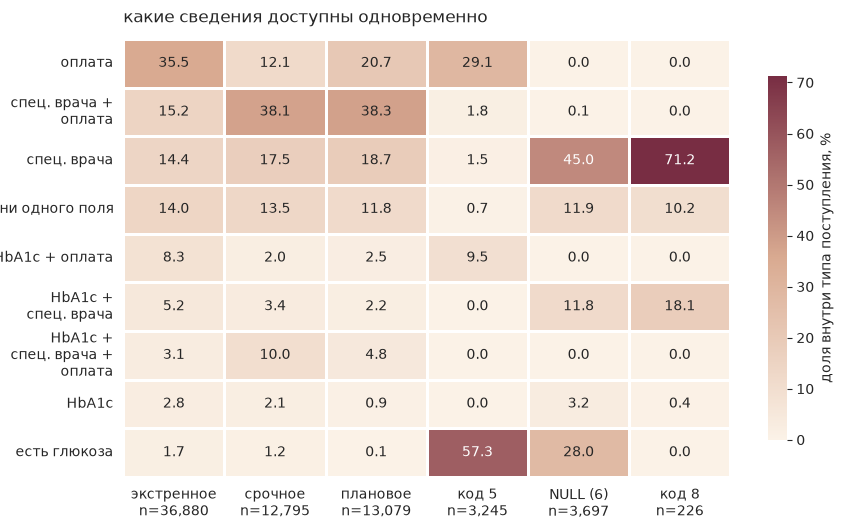

редкие типы поступления вне карты: 22 госпитализации


In [4]:
available = pd.DataFrame({
    "HbA1c": train["A1Cresult"].notna() & train["A1Cresult"].ne("None"),
    "глюкоза": train["max_glu_serum"].notna() & train["max_glu_serum"].ne("None"),
    "специальность": train["medical_specialty"].notna(),
    "оплата": train["payer_code"].notna(),
})
admission_labels = {
    1: "экстренное", 2: "срочное", 3: "плановое",
    5: "код 5", 6: "NULL (6)", 8: "код 8",
}
admission_order = list(admission_labels.values())
admission = train["admission_type_id"].map(admission_labels).rename("поступление")
patterns = pd.Series(
    [" + ".join(available.columns[row]) or "ни одного поля" for row in available.to_numpy()],
    index=train.index, name="доступные поля",
)
no_glucose = ~available["глюкоза"]
common_patterns = patterns.loc[admission.notna() & no_glucose].value_counts().head(8).index
shown_patterns = patterns.where(patterns.isin(common_patterns), "прочие без глюкозы")
shown_patterns = shown_patterns.mask(~no_glucose, "есть глюкоза")
pattern_counts = pd.crosstab(shown_patterns, admission).reindex(
    index=[*common_patterns, "есть глюкоза", "прочие без глюкозы"],
    columns=admission_order, fill_value=0,
)
pattern_counts = pattern_counts.loc[pattern_counts.sum(axis=1).gt(0)]
assert pattern_counts.to_numpy().sum() == admission.notna().sum()
pattern_rates = pattern_counts.div(pattern_counts.sum(), axis=1) * 100
pattern_rates.columns = [
    f"{label}\nn={size:,}" for label, size in pattern_counts.sum().items()
]

pattern_rates.index = [
    (label.replace(" + ", " +\n") if len(label) > 18 else label).replace("специальность", "спец. врача")
    for label in pattern_counts.index
]

with sns.axes_style("white"):
    fig, ax = plt.subplots(figsize=(11, 6))
    fig.subplots_adjust(left=0.26, right=0.95, bottom=0.17, top=0.90)
    sns.heatmap(
        pattern_rates, cmap=sns.blend_palette(["#FBF2E7", "#D9AA91", "#782D43"], as_cmap=True),
        annot=True, fmt=".1f", vmin=0, linewidths=1, linecolor="white",
        cbar_kws={"label": "доля внутри типа поступления, %", "shrink": 0.83}, ax=ax,
    )
    ax.set_title("какие сведения доступны одновременно", loc="left", pad=12)
    ax.set(xlabel=None, ylabel=None)
    ax.tick_params(axis="both", labelrotation=0)
plt.show()

print(f"редкие типы поступления вне карты: {admission.isna().sum()} госпитализации")

#### Сколько полей доступно и как это связано с меткой

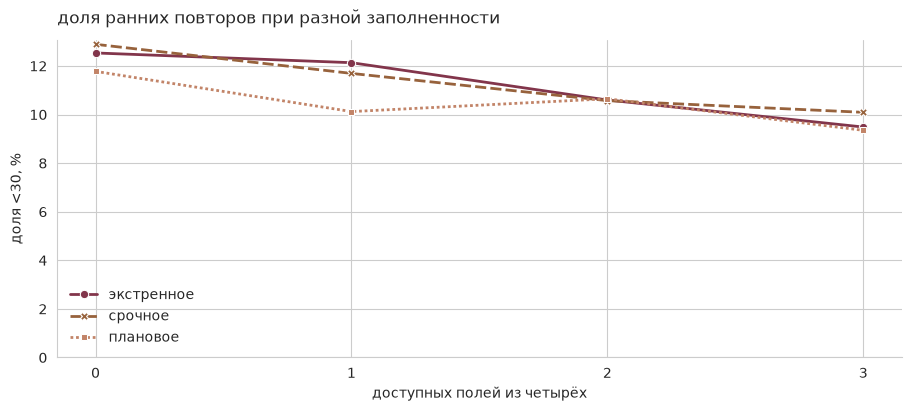

по всей обучающей выборке
                     n   rate
доступных полей              
0                8,903 12.55%
1               32,502 11.50%
2               24,809 10.79%
3                3,730 10.00%

число госпитализаций в группах графика
доступных полей       0        1        2       3
поступление                                      
экстренное       5146.0  19525.0  10965.0  1244.0
срочное          1730.0   4071.0   5666.0  1328.0
плановое         1537.0   5276.0   5635.0   631.0


In [5]:
coverage_size = available.sum(axis=1).rename("доступных полей")
outcome = train["readmitted_30d"]
coverage_summary = outcome.groupby(coverage_size).agg(n="size", rate="mean")
coverage_by_admission = outcome.groupby([admission, coverage_size]).agg(n="size", rate="mean")
groups = admission_order[:3]
coverage_plot = coverage_by_admission.loc[groups].reset_index()
coverage_plot["доля <30, %"] = coverage_plot["rate"] * 100
assert coverage_summary["n"].sum() == len(train)

with sns.axes_style("whitegrid", {"axes.grid.axis": "y"}):
    fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
    sns.lineplot(
        data=coverage_plot, x="доступных полей", y="доля <30, %",
        hue="поступление", style="поступление", markers=True,
        hue_order=groups, style_order=groups, palette=["#82354B", "#97623C", "#C28468"], linewidth=2, ax=ax,
    )
    ax.set_title("доля ранних повторов при разной заполненности", loc="left", pad=12)
    ax.set(xticks=sorted(coverage_size.unique()), xlabel="доступных полей из четырёх", ylim=(0, None))
    ax.legend(title=None, frameon=False)
    sns.despine(ax=ax)
plt.show()

print("по всей обучающей выборке")
print(coverage_summary.to_string(formatters={"n": "{:,}".format, "rate": "{:.2%}".format}))
print("\nчисло госпитализаций в группах графика")
print(coverage_by_admission["n"].unstack().loc[groups].to_string())

**Вывод.** При переходе от нуля доступных полей к трём доля `<30` ниже во всех трёх распространённых типах поступления. Для плановых госпитализаций линия не монотонна. Из 3 690 записей с измеренной глюкозой 2 894 относятся к кодам поступления `5` и `6`.

### Равный вес пациентов

#### HbA1c и инсулин

В обычном расчёте каждая госпитализация имеет вес 1. Во втором варианте каждой записи присваиваем вес, обратный числу строк пациента на `train`. Суммарный вес каждого пациента по всем его записям получается равным 1.

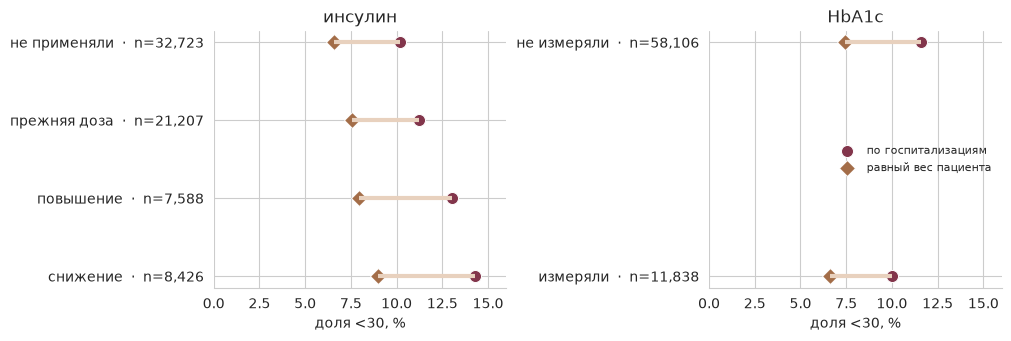

инсулин
                  n   rate weighted
insulin                            
не применяли  32723 10.19%    6.59%
прежняя доза  21207 11.22%    7.55%
повышение      7588 13.01%    7.93%
снижение       8426 14.31%    8.99%

HbA1c
                 n   rate weighted
HbA1c                             
не измеряли  58106 11.57%    7.41%
измеряли     11838 10.02%    6.63%



In [6]:
patient_n = train.groupby("patient_nbr")["patient_nbr"].transform("size")
patient_weight = 1 / patient_n
assert np.allclose(patient_weight.groupby(train["patient_nbr"]).sum(), 1)

weighted_reports = {}
medication_groups = [
    ("инсулин", train["insulin"].map({
        "No": "не применяли", "Steady": "прежняя доза", "Up": "повышение", "Down": "снижение",
    }), ["не применяли", "прежняя доза", "повышение", "снижение"]),
    ("HbA1c", available["HbA1c"].map({False: "не измеряли", True: "измеряли"}),
     ["не измеряли", "измеряли"]),
]
with sns.axes_style("whitegrid", {"axes.grid.axis": "x"}):
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.3), sharex=True, layout="constrained")
    for (title, group, order), ax in zip(medication_groups, axes, strict=True):
        report = outcome.groupby(group).agg(n="size", rate="mean").reindex(order)
        report["weighted"] = (outcome * patient_weight).groupby(group).sum().div(
            patient_weight.groupby(group).sum()
        ).reindex(order)
        weighted_reports[title] = report
        y = np.arange(len(order))
        raw, weighted = report["rate"] * 100, report["weighted"] * 100
        ax.hlines(y, weighted, raw, color="#E8D1BE", linewidth=3)
        sns.scatterplot(x=raw, y=y, color="#82354B", s=75, label="по госпитализациям", ax=ax)
        sns.scatterplot(x=weighted, y=y, color="#A36D48", marker="D", s=65, label="равный вес пациента", ax=ax)
        ax.set_yticks(y, [f"{label}  ·  n={n:,}" for label, n in zip(order, report["n"], strict=True)])
        ax.invert_yaxis()
        ax.set(title=title, xlabel="доля <30, %", ylabel=None, xlim=(0, 16))
        sns.despine(ax=ax, left=True)
    axes[0].get_legend().remove()
    axes[1].legend(title=None, frameon=False, fontsize=8)
plt.show()

for title, report in weighted_reports.items():
    print(title)
    print(report.to_string(formatters={"rate": "{:.2%}".format, "weighted": "{:.2%}".format}), end="\n\n")

**Вывод.** Порядок четырёх групп по инсулину сохранился при равном весе пациентов. Разница между измеренным и неизмеренным HbA1c уменьшилась с 1,55 до 0,78 п.п. Оба сравнения описывают наблюдаемые группы.

### Переводы и границы госпитализации

#### Сравнение вариантов выборки

Сравниваем исходный `train` с двумя вариантами. В узком исключаем коды `2`, `9` и `15`: перевод в другую краткосрочную больницу, оформление стационарного поступления в том же учреждении и перевод в койку длительного ухода внутри учреждения. В широком дополнительно исключаем другие явно указанные стационарные переводы (`5`, `22`, `23`, `27`, `28`, `29`, `30`). Сравнение проверяет чувствительность состава выборки. По CSV нельзя установить, какие переводы действительно продолжают тот же эпизод лечения.

                       госпитализации пациенты ранние повторы доля <30
текущая выборка                69,944   49,307          7,907   11.30%
без узкой группы               68,367   48,427          7,639   11.17%
без расширенной группы         65,748   46,992          7,013   10.67%


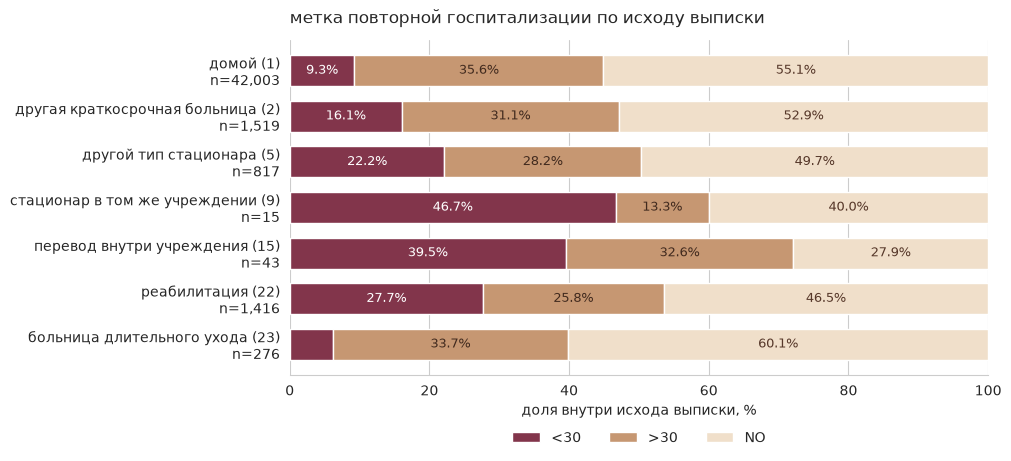

In [7]:
disposition = train["discharge_disposition_id"]
narrow_codes = {2, 9, 15}
broad_codes = narrow_codes | {5, 22, 23, 27, 28, 29, 30}
assert broad_codes <= set(id_mapping.loc[id_mapping["field"].eq("discharge_disposition_id"), "code"])
scenarios = {
    "текущая выборка": train,
    "без узкой группы": train.loc[~disposition.isin(narrow_codes)],
    "без расширенной группы": train.loc[~disposition.isin(broad_codes)],
}
scenario_summary = pd.DataFrame({
    label: {
        "госпитализации": len(part),
        "пациенты": part["patient_nbr"].nunique(),
        "ранние повторы": part["readmitted_30d"].sum(),
        "доля <30": part["readmitted_30d"].mean(),
    }
    for label, part in scenarios.items()
}).T
assert scenario_summary["госпитализации"].is_monotonic_decreasing
print(scenario_summary.to_string(formatters={
    "госпитализации": "{:,.0f}".format, "пациенты": "{:,.0f}".format,
    "ранние повторы": "{:,.0f}".format, "доля <30": "{:.2%}".format,
}))

disposition_names = {
    1: "домой", 2: "другая краткосрочная больница", 5: "другой тип стационара",
    9: "стационар в том же учреждении", 15: "перевод внутри учреждения",
    22: "реабилитация", 23: "больница длительного ухода",
}
disposition_counts = pd.crosstab(disposition, train["readmitted"]).reindex(
    index=list(disposition_names), columns=["<30", ">30", "NO"], fill_value=0,
)
disposition_rates = disposition_counts.div(disposition_counts.sum(axis=1), axis=0) * 100
assert np.allclose(disposition_rates.sum(axis=1), 100)

with sns.axes_style("whitegrid", {"axes.grid.axis": "x"}):
    fig, ax = plt.subplots(figsize=(10, 4.5), layout="constrained")
    labels = [
        f"{disposition_names[value]} ({value})\nn={disposition_counts.loc[value].sum():,}"
        for value in disposition_counts.index
    ]
    left = np.zeros(len(labels))
    for target, color, text_color in [("<30", "#82354B", "white"), (">30", "#C69772", "#412A1E"), ("NO", "#F0DFCA", "#563729")]:
        width = disposition_rates[target].to_numpy()
        bars = ax.barh(labels, width, left=left, color=color, label=target, height=0.68)
        ax.bar_label(bars, labels=[f"{value:.1f}%" if value >= 7 else "" for value in width],
                     label_type="center", color=text_color, fontsize=9)
        left += width
    ax.invert_yaxis()
    ax.set_title("метка повторной госпитализации по исходу выписки", loc="left", pad=12)
    ax.set(xlabel="доля внутри исхода выписки, %", xlim=(0, 100))
    ax.legend(title=None, loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=3, frameon=False)
    sns.despine(ax=ax, left=True)
plt.show()

In [8]:
transfer_admission_codes = {4, 5, 6, 10, 22, 25, 26}
transfer_context = (
    train.loc[disposition.isin(disposition_names)]
    .assign(поступил_переводом=train["admission_source_id"].isin(transfer_admission_codes))
    .groupby("discharge_disposition_id")
    .agg(госпитализации=("encounter_id", "size"),
         медиана_дней=("time_in_hospital", "median"),
         доля_поступивших_переводом=("поступил_переводом", "mean"))
    .rename(index=disposition_names)
)
print(transfer_context.to_string(formatters={"доля_поступивших_переводом": "{:.1%}".format}))


                               госпитализации  медиана_дней доля_поступивших_переводом
discharge_disposition_id                                                              
домой                                   42003           3.0                       5.5%
другая краткосрочная больница            1519           3.0                       6.8%
другой тип стационара                     817           5.0                      11.1%
стационар в том же учреждении              15           4.0                       0.0%
перевод внутри учреждения                  43           6.0                       0.0%
реабилитация                             1416           5.0                       3.5%
больница длительного ухода                276           7.0                       5.8%


**Вывод.** Доля `<30` в текущей выборке составляет 11,30%. При узком исключении она составляет 11,17%, при широком 10,67%. Широкий вариант убирает 4 196 госпитализаций и 894 ранних повтора. Пока это проверка состава выборки. Для сравнения качества моделей нужен отдельный эксперимент.

### Чувствительность состава выборки

#### Что меняет исключение выписок в хоспис

Сравниваем состав текущего `train` с вариантами без хосписа, без узкой группы переводов и без обеих групп. Смотрим, сколько госпитализаций, пациентов и ранних повторов теряется.

In [9]:
is_hospice = disposition.isin([13, 14])
is_narrow_transfer = disposition.isin(narrow_codes)
assert not (is_hospice & is_narrow_transfer).any()

sample_masks = {
    "текущая выборка": pd.Series(True, index=train.index),
    "без хосписа": ~is_hospice,
    "без узкой группы переводов": ~is_narrow_transfer,
    "без хосписа и узкой группы": ~(is_hospice | is_narrow_transfer),
}
sample_sensitivity = pd.DataFrame([
    {
        "вариант": label,
        "госпитализации": len(part),
        "пациенты": part["patient_nbr"].nunique(),
        "ранние повторы": part["readmitted_30d"].sum(),
        "доля <30": part["readmitted_30d"].mean(),
    }
    for label, mask in sample_masks.items()
    for part in [train.loc[mask]]
]).set_index("вариант")
sample_sensitivity["убрали строк"] = len(train) - sample_sensitivity["госпитализации"]
sample_sensitivity["убрали ранних повторов"] = (
    train["readmitted_30d"].sum() - sample_sensitivity["ранние повторы"]
)
assert sample_sensitivity.loc["без хосписа", "убрали строк"] == is_hospice.sum()
print(sample_sensitivity.to_string(formatters={"доля <30": "{:.2%}".format}))


                            госпитализации  пациенты  ранние повторы доля <30  убрали строк  убрали ранних повторов
вариант                                                                                                            
текущая выборка                      69944     49307            7907   11.30%             0                       0
без хосписа                          69395     48988            7878   11.35%           549                      29
без узкой группы переводов           68367     48427            7639   11.17%          1577                     268
без хосписа и узкой группы           67818     48106            7610   11.22%          2126                     297


**Вывод.** Исключение хосписа убирает 549 госпитализаций, включая 29 ранних повторов. Доля `<30` меняется с 11,30% до 11,35%. Основное правило выборки можно оставить прежним, если прогноз относится ко всем выписанным живыми.

#### Насколько сопоставим состав групповых фолдов

На данных разработки объединяем исходные `train` и `validation`. Делим их на пять фолдов по пациентам без стратификации по метке, чтобы увидеть естественные различия размера и доли `<30`. Это проверка состава выборок перед моделированием.

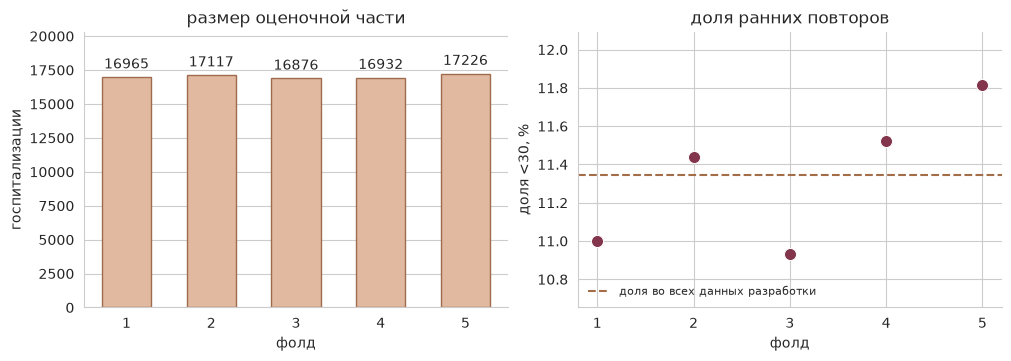

      пациенты  госпитализации доля <30, %
фолд                                      
1        11975           16965       11.00
2        11975           17117       11.44
3        11975           16876       10.93
4        11974           16932       11.52
5        11974           17226       11.81


In [10]:
holdout = cohort.iloc[holdout_idx]
val_idx, _ = next(
    GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=42)
    .split(holdout, groups=holdout["patient_nbr"])
)
validation = holdout.iloc[val_idx]
assert not train["patient_nbr"].isin(validation["patient_nbr"]).any()
development = pd.concat([train, validation])
groups = development["patient_nbr"]

fold_rows = []
seen = set()
splitter = GroupKFold(n_splits=5, shuffle=True, random_state=42)
for fold, (fit_idx, fold_val_idx) in enumerate(splitter.split(development, groups=groups), start=1):
    part = development.iloc[fold_val_idx]
    fold_patients = set(part["patient_nbr"])
    assert not fold_patients.intersection(groups.iloc[fit_idx])
    assert not seen.intersection(fold_patients)
    seen.update(fold_patients)
    fold_rows.append({
        "фолд": str(fold),
        "пациенты": len(fold_patients),
        "госпитализации": len(part),
        "доля <30, %": part["readmitted_30d"].mean() * 100,
    })
fold_summary = pd.DataFrame(fold_rows).set_index("фолд")
assert len(seen) == groups.nunique()
assert fold_summary["госпитализации"].sum() == len(development)

with sns.axes_style("whitegrid", {"axes.grid.axis": "y"}):
    fig, (size_ax, rate_ax) = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
    sns.barplot(x=fold_summary.index, y=fold_summary["госпитализации"],
                color="#E0B9A0", edgecolor="#A06B4D", saturation=1, width=0.58, ax=size_ax)
    size_ax.bar_label(size_ax.containers[0], fmt="%d", padding=4)
    size_ax.set(title="размер оценочной части", xlabel="фолд", ylabel="госпитализации",
                ylim=(0, fold_summary["госпитализации"].max() * 1.18))

    rates = fold_summary["доля <30, %"]
    sns.scatterplot(x=fold_summary.index, y=rates, color="#82354B", s=75, ax=rate_ax)
    rate_ax.axhline(development["readmitted_30d"].mean() * 100, color="#A36D48",
                   linestyle="--", label="доля во всех данных разработки")
    rate_ax.set(title="доля ранних повторов", xlabel="фолд", ylabel="доля <30, %",
                ylim=(rates.min() - 0.28, rates.max() + 0.28))
    rate_ax.legend(loc="lower left", frameon=False, fontsize=8)
    sns.despine(fig=fig)
plt.show()

print(fold_summary.to_string(formatters={"доля <30, %": "{:.2f}".format}))


**Вывод.** В оценочной части каждого фолда около 12 тысяч пациентов и от 16 876 до 17 226 госпитализаций. Доля `<30` находится между 10,93% и 11,81%. Это показывает разброс состава фолдов. Разброс качества можно будет измерить после обучения моделей.